In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import glob
import os

In [ ]:

# ---------------------------------------------------------
# CONFIGURATION
# ---------------------------------------------------------
# Paths to your cell types (Must match alphabetical order of the script)
# Based on your manifest: B_Cell, Macrophage, T_Cell
CELL_TYPES = ["B_Cell", "Macrophage", "T_Cell"]

# Path to a shard generated by the debug script
SHARD_PATH = "/mnt/data_sda/jdearborn/scratch/Imm_cell_rMATS/data_labeling/results/labelled_data/windowed_multitask_confidence/train/shard_0002.npz"

In [3]:
# ---------------------------------------------------------
# UTILS
# ---------------------------------------------------------

def load_shard(path):
    if not os.path.exists(path):
        print(f"File not found: {path}")
        return None
    return np.load(path, allow_pickle=True)

def decode_seq(one_hot_seq):
    """Decodes (L, 4) one-hot to string."""
    idx_to_base = {0: 'A', 1: 'C', 2: 'G', 3: 'T'}
    is_N = one_hot_seq.sum(axis=1) == 0
    indices = one_hot_seq.argmax(axis=1)
    seq_chars = []
    for i, idx in enumerate(indices):
        if is_N[i]: seq_chars.append('N')
        else: seq_chars.append(idx_to_base[idx])
    return "".join(seq_chars)

def inspect_multitask_example(shard_path, example_idx=0):
    data = load_shard(shard_path)
    if data is None: return

    # Unpack
    seq = data['sequence'][example_idx]      # (L, 4)
    targets = data['targets'][example_idx]   # (Bins, Tasks)
    mask = data['mask'][example_idx]         # (Bins, Tasks)
    chrom = str(data['chrom'][example_idx])
    start = data['window_start'][example_idx]
    end = data['window_end'][example_idx]
    has_signal = data['has_signal'][example_idx]

    n_bins, n_tasks = targets.shape
    
    print(f"--- Example {example_idx} from {os.path.basename(shard_path)} ---")
    print(f"Location: {chrom}:{start}-{end}")
    print(f"Has Signal Flag: {has_signal}")
    print(f"Target Shape: {targets.shape} (Bins, Tasks)")
    
    # Check alignment with expected cell types
    if n_tasks != len(CELL_TYPES):
        print(f"⚠️ WARNING: Found {n_tasks} tasks in file, but config has {len(CELL_TYPES)} names.")
        task_names = [f"Task_{i}" for i in range(n_tasks)]
    else:
        task_names = CELL_TYPES

    # 1. Visualization
    fig, axes = plt.subplots(n_tasks + 1, 1, figsize=(12, 3 * (n_tasks + 1)), sharex=True)
    
    # Plot Sequence Density (N content vs GC content roughly)
    # Just plotting GC content density for context
    gc_track = seq[:, 1] + seq[:, 2] # C+G
    # Downsample seq track to match bin size for plotting
    bin_size = seq.shape[0] // n_bins
    gc_binned = gc_track.reshape(n_bins, bin_size).mean(axis=1)
    
    axes[0].plot(gc_binned, color='grey', alpha=0.5, label="GC Content")
    axes[0].set_ylabel("GC Freq")
    axes[0].set_title(f"Genomic Context ({chrom}:{start}-{end})")
    axes[0].legend(loc="upper right")

    # Plot Each Task
    for i, task in enumerate(task_names):
        ax = axes[i+1]
        
        # Plot Mask (Where we have coverage)
        m = mask[:, i]
        t = targets[:, i]
        
        # Shade regions with coverage
        active_bins = np.where(m > 0)[0]
        if len(active_bins) > 0:
            # Add colored spans for coverage
            # Just plotting the line is usually enough if it's sparse
            pass

        # Plot Data
        ax.plot(t, label=f"{task} PSI", color=f"C{i}")
        
        # Highlight non-zero events
        if t.max() > 0:
            ax.set_ylim(-0.1, 1.1)
        
        # Stats for this task
        avg_psi = t[m>0].mean() if m.sum() > 0 else 0.0
        ax.text(0.01, 0.85, f"Avg PSI (in events): {avg_psi:.2f}\nBins Covered: {m.sum()}", 
                transform=ax.transAxes, fontsize=9, bbox=dict(facecolor='white', alpha=0.8))

        ax.set_ylabel("PSI")
        ax.legend(loc="upper right")

    plt.xlabel("Bins (32bp)")
    plt.tight_layout()
    plt.show()

    # 2. Sanity Checks
    print("\n--- Logic Checks ---")
    
    # A. Check for "Ghost" signals (Targets without mask)
    ghosts = (targets > 0) & (mask == 0)
    if ghosts.any():
        print("❌ CRITICAL: Found non-zero targets where mask is 0!")
    else:
        print("✅ Mask consistency: OK")

    # B. Check Multitask Co-occurrence
    # Do different tasks have data in the same bins?
    cooccurrence = (mask.sum(axis=1) > 1).sum()
    print(f"Bins with overlapping coverage from multiple cell types: {cooccurrence}")
    if cooccurrence > 0:
        print("   (This is good! It means we have shared exons covered by multiple cell types)")
    
    # C. Check Values
    if targets.max() > 1.0 or targets.min() < 0.0:
         print(f"❌ CRITICAL: PSI values out of range [0,1]. Min: {targets.min()}, Max: {targets.max()}")
    else:
         print("✅ PSI Value Range: OK [0, 1]")

--- Example 2 from shard_0002.npz ---
Location: chr1:138011681-138535969
Has Signal Flag: 1.0
Target Shape: (16384, 3) (Bins, Tasks)


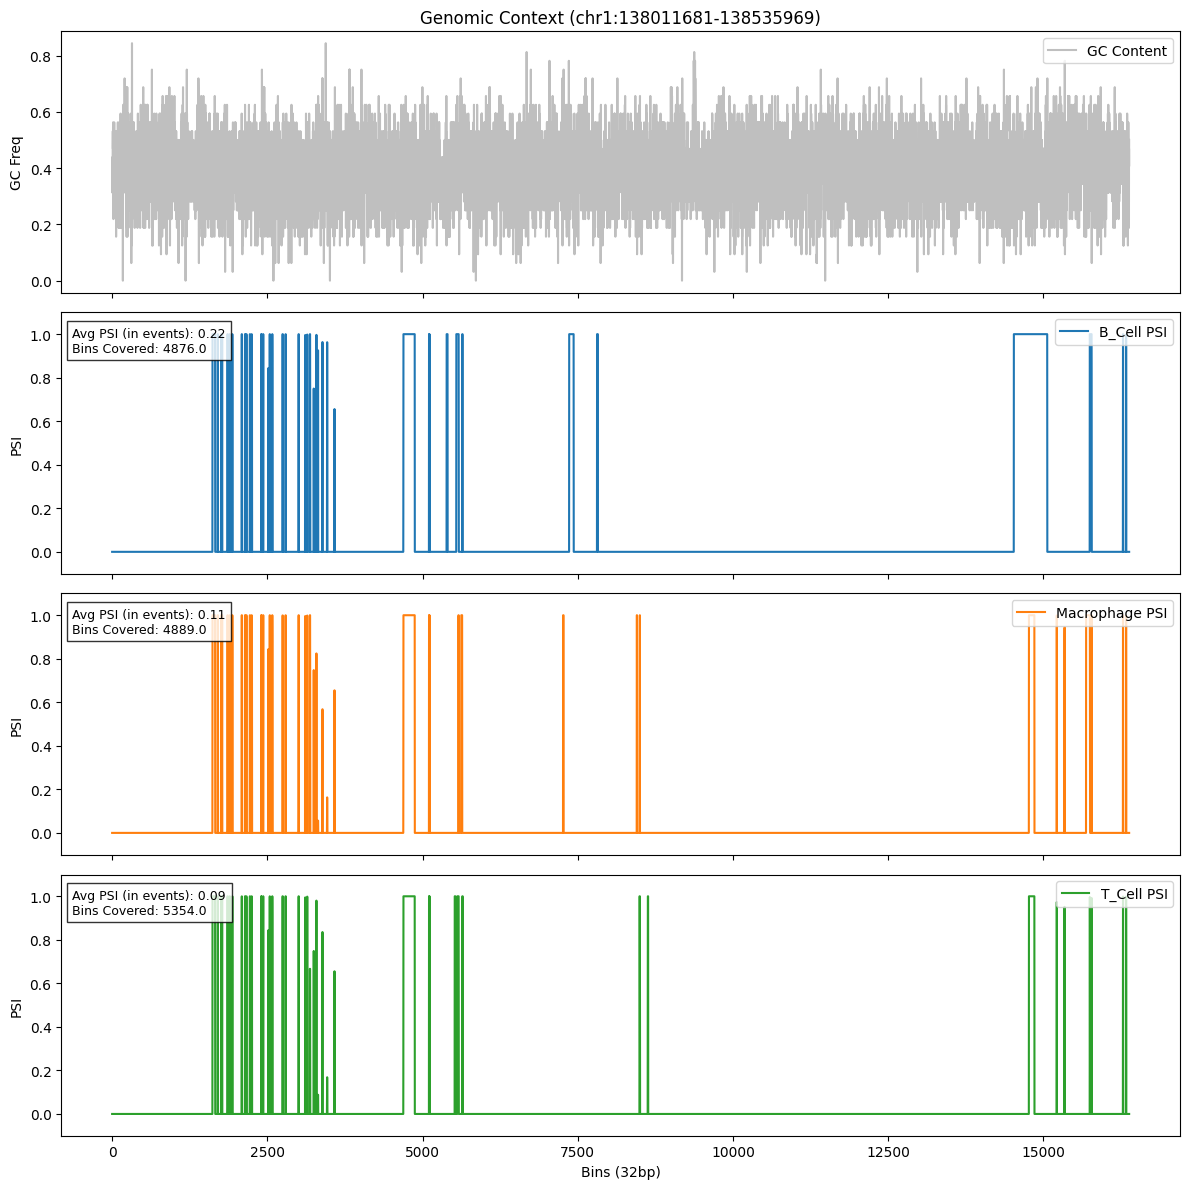


--- Logic Checks ---
✅ Mask consistency: OK
Bins with overlapping coverage from multiple cell types: 4861
   (This is good! It means we have shared exons covered by multiple cell types)
✅ PSI Value Range: OK [0, 1]


In [19]:
# Usage
if __name__ == "__main__":
    # Test on the first example
    inspect_multitask_example(SHARD_PATH, example_idx=2)
    # Test on a later example to try and find signal
    # inspect_multitask_example(SHARD_PATH, example_idx=5)

--- Example 1 from shard_0002.npz ---
Location: chr1:137749532-138273820
Has Signal Flag: 1.0
Target Shape: (16384, 3) (Bins, Tasks)


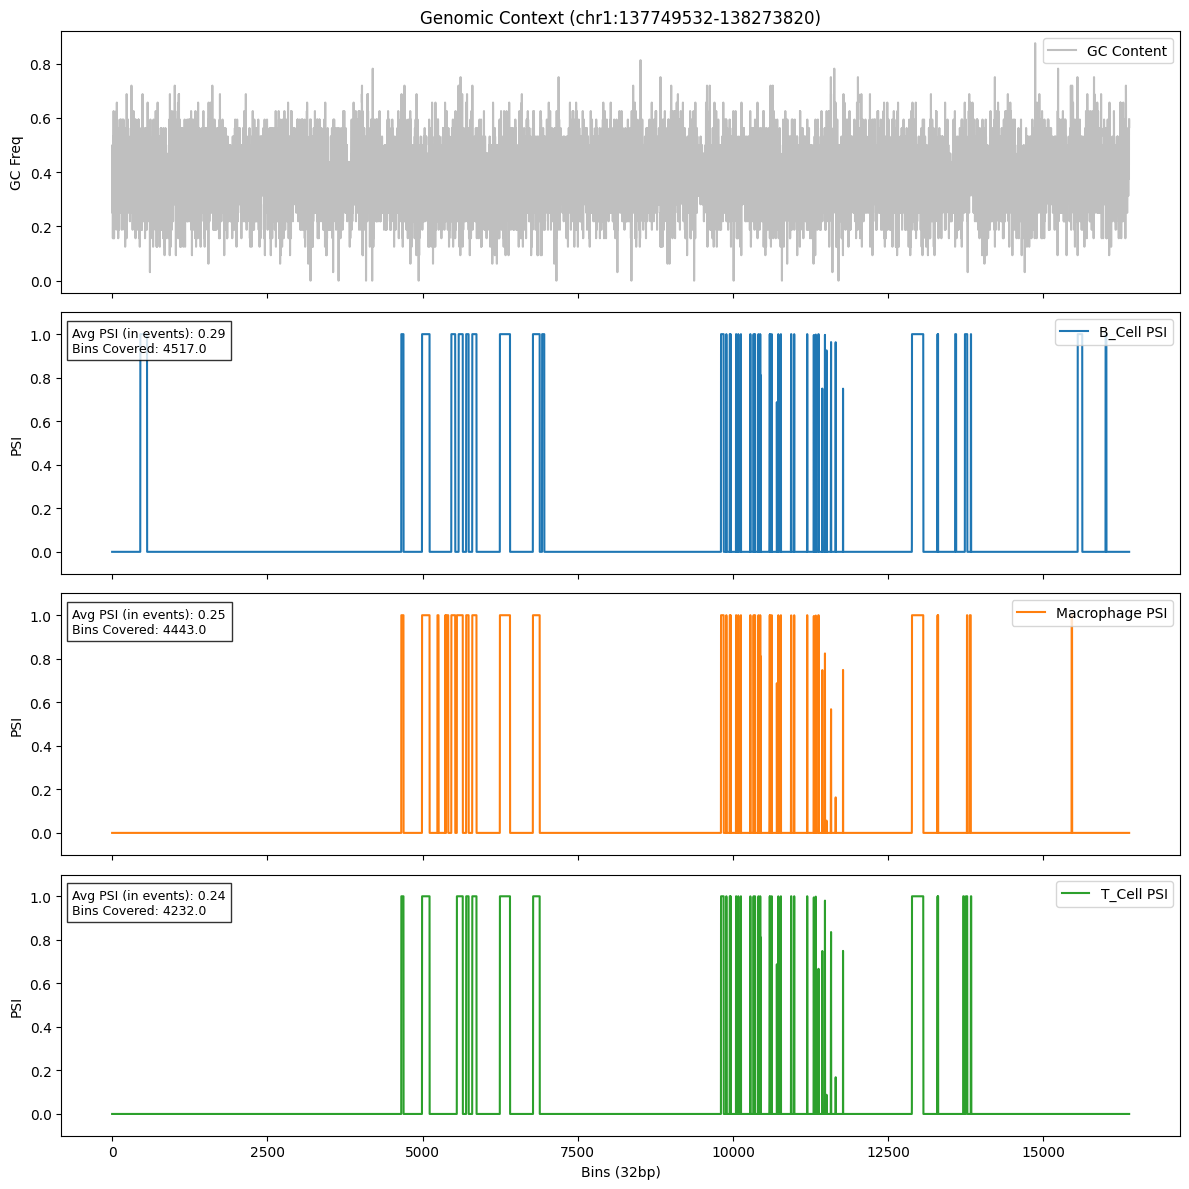


--- Logic Checks ---
✅ Mask consistency: OK
Bins with overlapping coverage from multiple cell types: 4283
   (This is good! It means we have shared exons covered by multiple cell types)
✅ PSI Value Range: OK [0, 1]


In [20]:
# Usage
if __name__ == "__main__":
    # Test on the first example
    inspect_multitask_example(SHARD_PATH, example_idx=1)
    # Test on a later example to try and find signal
    # inspect_multitask_example(SHARD_PATH, example_idx=5)

In [21]:
# examine a line of the npz file
def examine_line(npz_path, line_idx):
    data = np.load(npz_path, allow_pickle=True)
    seq = data['sequence'][line_idx]
    targets = data['targets'][line_idx]
    mask = data['mask'][line_idx]
    chrom = data['chrom'][line_idx]
    start = data['window_start'][line_idx]
    end = data['window_end'][line_idx]
    has_signal = data['has_signal'][line_idx]

    print(f"Chromosome: {chrom}")
    print(f"Window: {start}-{end}")
    print(f"Has Signal: {has_signal}")
    print(f"Sequence Shape: {seq.shape}")
    print(f"Targets Shape: {targets.shape}")
    print(f"Mask Shape: {mask.shape}")

    # Decode sequence
    decoded_seq = decode_seq(seq)
    print(f"Decoded Sequence (first 100 bases): {decoded_seq[:100]}")

    # Print targets and mask
    print("Targets:")
    print(targets)
    print("Mask:")
    print(mask)

# Example usage
# examine_line(SHARD_PATH, 0)

In [35]:
examine_line(SHARD_PATH, 4)

Chromosome: chr1
Window: 4318224-4842512
Has Signal: 1.0
Sequence Shape: (524288, 4)
Targets Shape: (16384, 3)
Mask Shape: (16384, 3)
Decoded Sequence (first 100 bases): GAATATACAGTCAGACAAACATGAAGAAAGGATTCAGGAGTCCTTCCCCGGGTGCTGAATTATCTCTTATGGATAGAAAGAGGAAGTGAAAATAAAAAGG
Targets:
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 ...
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]
Mask:
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]
 ...
 [0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]


In [36]:
# examine how many lines have signal
data = np.load(SHARD_PATH, allow_pickle=True)
has_signal_array = data['has_signal']
num_with_signal = np.sum(has_signal_array)
total_examples = has_signal_array.shape[0]
print(f"Examples with signal: {num_with_signal} / {total_examples} ({(num_with_signal/total_examples)*100:.2f}%)")


Examples with signal: 231.0 / 256 (90.23%)


In [37]:
SHARD_PATH = "/mnt/data_sda/jdearborn/scratch/Imm_cell_rMATS/data_labeling/results/labelled_data/windowed_multitask_robust/train/shard_0002.npz"

In [38]:
# subset npz file for only chrom, start, end
def subset_npz_coord(input_path):
    data = np.load(input_path, allow_pickle=True)
    subset_data = {
        'chrom': data['chrom'],
        'window_start': data['window_start'],
        'window_end': data['window_end']
    }
    return subset_data

coords = subset_npz_coord(SHARD_PATH)


In [39]:
# print 10 entries
for i in range(10):
    print(f"{coords['chrom'][i]}:{coords['window_start'][i]}-{coords['window_end'][i]}")

chr1:137487389-138011677
chr1:137749532-138273820
chr1:138011681-138535969
chr1:138273797-138798085
chr1:138535967-139060255
chr1:138798084-139322372
chr1:139060241-139584529
chr1:139322389-139846677
chr1:139584525-140108813
chr1:139846662-140370950


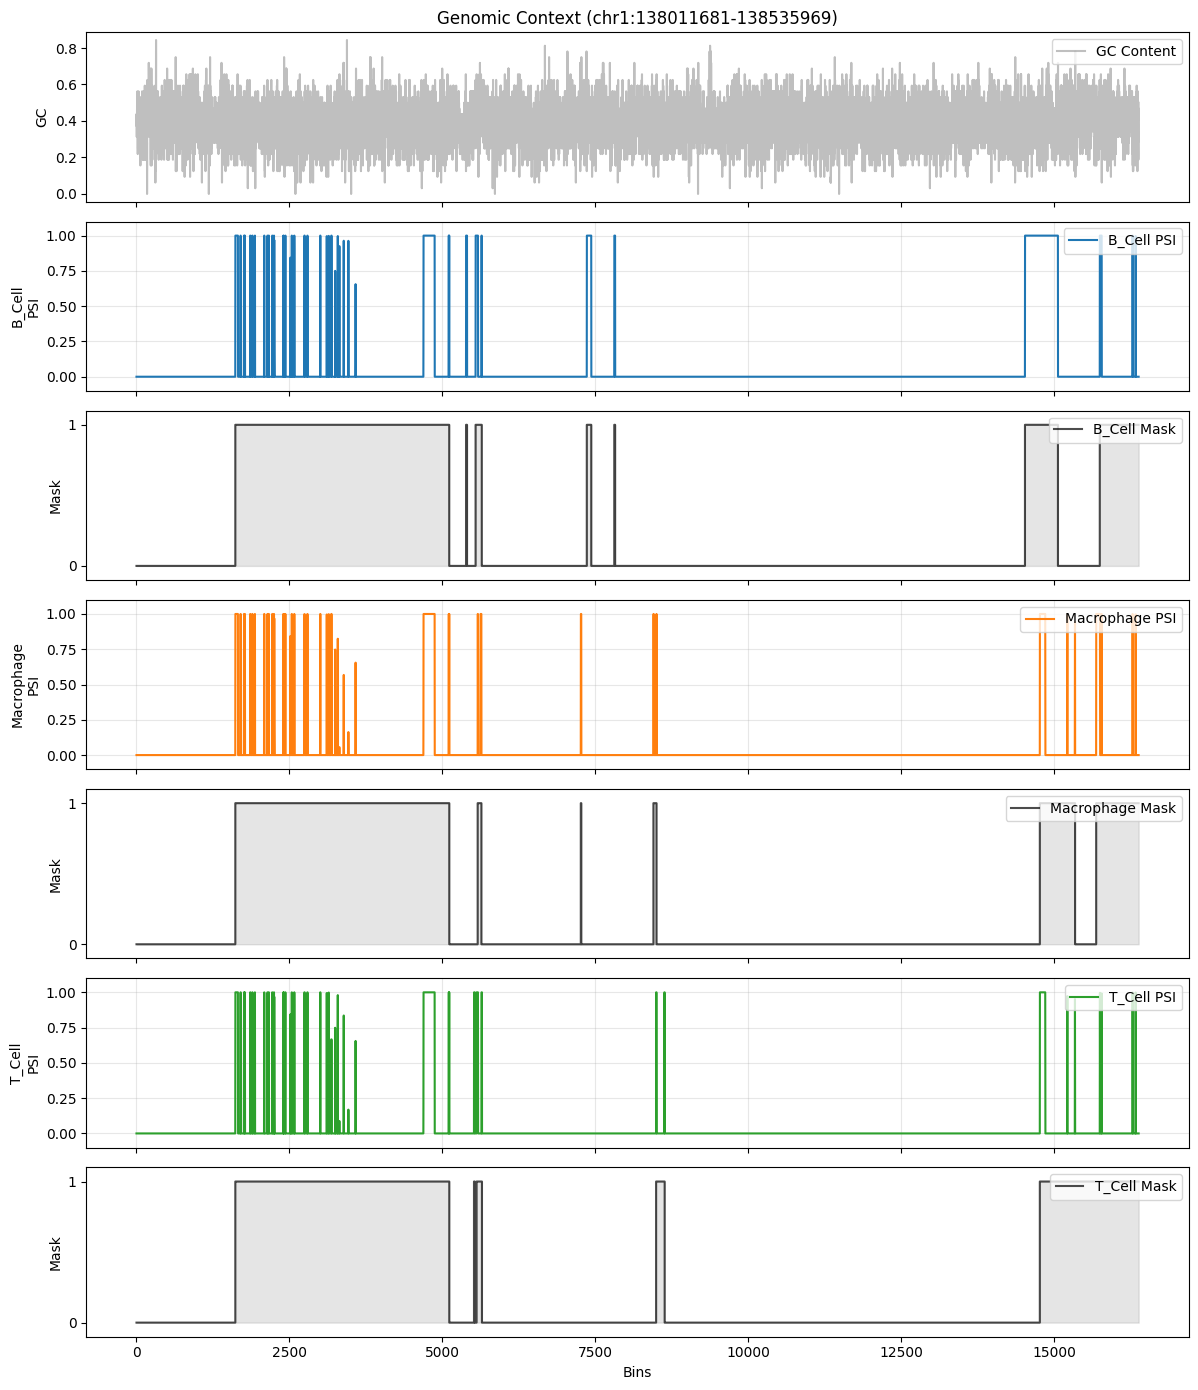

In [22]:
def plot_psi_and_mask_example(shard_path, example_idx=0):
    data = load_shard(shard_path)
    if data is None: return

    # Unpack
    seq = data['sequence'][example_idx]
    targets = data['targets'][example_idx]
    mask = data['mask'][example_idx]
    chrom = str(data['chrom'][example_idx])
    start = data['window_start'][example_idx]
    end = data['window_end'][example_idx]
    
    n_bins, n_tasks = targets.shape
    task_names = CELL_TYPES if n_tasks == len(CELL_TYPES) else [f"Task_{i}" for i in range(n_tasks)]

    # Layout: GC Content + (PSI + Mask) for each task
    # We will create 1 row for GC, and then 2 rows per task (one for PSI, one for Mask)
    total_plots = 1 + 2 * n_tasks
    fig, axes = plt.subplots(total_plots, 1, figsize=(12, 2 * total_plots), sharex=True)

    # 1. GC Content
    gc_track = seq[:, 1] + seq[:, 2] 
    bin_size = seq.shape[0] // n_bins
    gc_binned = gc_track.reshape(n_bins, bin_size).mean(axis=1)
    
    axes[0].plot(gc_binned, color='grey', alpha=0.5, label="GC Content")
    axes[0].set_ylabel("GC")
    axes[0].set_title(f"Genomic Context ({chrom}:{start}-{end})")
    axes[0].legend(loc="upper right")

    # 2. Per Task
    for i, task in enumerate(task_names):
        # Indices in axes array
        # 0 is GC
        # 1 is Task 0 PSI
        # 2 is Task 0 Mask
        # 3 is Task 1 PSI
        # ...
        ax_psi = axes[1 + i*2]
        ax_mask = axes[1 + i*2 + 1]

        t = targets[:, i]
        m = mask[:, i]

        # Plot PSI
        ax_psi.plot(t, label=f"{task} PSI", color=f"C{i}")
        ax_psi.set_ylabel(f"{task}\nPSI")
        ax_psi.set_ylim(-0.1, 1.1)
        ax_psi.legend(loc="upper right")
        ax_psi.grid(True, alpha=0.3)

        # Plot Mask
        ax_mask.step(range(len(m)), m, where='mid', label=f"{task} Mask", color='black', alpha=0.7)
        ax_mask.fill_between(range(len(m)), m, step='mid', color='gray', alpha=0.2)
        ax_mask.set_ylabel("Mask")
        ax_mask.set_ylim(-0.1, 1.1)
        ax_mask.set_yticks([0, 1])
        ax_mask.legend(loc="upper right")

    plt.xlabel("Bins")
    plt.tight_layout()
    plt.show()

# Usage
plot_psi_and_mask_example(SHARD_PATH, example_idx=2)

In [ ]:
# Debug script check
print("Dummy cell to verify formatting")